# 08. Погодное покрытие актуальной аналитической базы

## 1. Завершенность обработки и происхождение

Результаты полного технического охвата по [протоколу](07_full_coverage_protocol.ipynb).
Все исходные аналитические записи сохранены. Флаги качества являются
диагностическими сценариями и не означают принятого исключения записей.
Обучение модели не выполнялось.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
protocol=json.loads((R/'11_full_protocol.json').read_text(encoding='utf8'))
progress=json.loads((R/'12_full_progress.json').read_text(encoding='utf8'))
integrity=json.loads((R/'12_full_integrity.json').read_text(encoding='utf8'))
assert integrity['all_source_rows_present_once'] and integrity['rows']==protocol['rows']
assert progress['complete'] and progress['completed']==progress['planned']==len(protocol['jobs'])
assert progress['rows_processed']==protocol['rows']
assert sum(j['go_arounds'] for j in progress['jobs'])==protocol['go_arounds']
for job in progress['jobs']:
    assert job['input_sha256']==protocol['input_sha256']
    path=DATA/'full/raw'/f"{job['airport']}_{job['year']}.csv"
    assert sha(path)==job['source']['sha256']
    for file in job['files']:
        assert sha(DATA/'full/results'/file['name'])==file['sha256']
display(pd.DataFrame(progress['jobs'])[['airport','year','rows','go_arounds','raw_reports','unique_reports','identical_duplicates','ambiguous_times','residual_reports','core_failed_reports']])
scenario=pd.read_csv(R/'12_full_scenarios.csv')
residual=pd.read_csv(R/'12_full_residuals.csv',keep_default_na=False)
summary=scenario.groupby(['latency_minutes','maximum_age_minutes','quality','exclude_cor','GoA'])[['total','candidates']].sum().reset_index()
summary['coverage_percent']=100*summary.candidates/summary.total
display(summary.loc[summary.maximum_age_minutes.eq(60)&summary.latency_minutes.eq(0)])
summary.to_csv(R/'12_full_summary.csv',index=False)


,airport,year,rows,go_arounds,raw_reports,unique_reports,identical_duplicates,ambiguous_times,residual_reports,core_failed_reports
0,EDDB,2019,28762,65,17555,17555,0,0,57,57
1,EDDB,2020,13117,35,17609,17609,0,0,58,58
2,EDDB,2021,35640,99,17561,17561,0,0,44,40
3,EDDB,2022,50306,153,17558,17558,0,0,19,16
4,EDDB,2023,20511,75,7295,7295,0,0,2,1
...,...,...,...,...,...,...,...,...,...,...
88,LSZH,2019,110036,366,17194,17194,0,0,0,0
89,LSZH,2020,43458,190,17238,17238,0,0,9,1
90,LSZH,2021,51260,175,17466,17466,0,0,53,0
91,LSZH,2022,78758,282,17557,17557,0,0,3,3


,latency_minutes,maximum_age_minutes,quality,exclude_cor,GoA,total,candidates,coverage_percent
12,0,60,core_validated,False,False,6313136,6306543,99.895567
13,0,60,core_validated,False,True,18349,18325,99.869203
14,0,60,core_validated,True,False,6313136,6032047,95.547554
15,0,60,core_validated,True,True,18349,17298,94.272167
16,0,60,decoded_candidate,False,False,6313136,6304191,99.858311
17,0,60,decoded_candidate,False,True,18349,18307,99.771105
18,0,60,decoded_candidate,True,False,6313136,6029779,95.511628
19,0,60,decoded_candidate,True,True,18349,17280,94.174069
20,0,60,observation,False,False,6313136,6310962,99.965564
21,0,60,observation,False,True,18349,18344,99.972751


## 2. Покрытие по аэропортам и месяцам

Покрытие наблюдением означает наличие однозначного предыдущего METAR в пределах
порога давности. Оно не требует полного декодирования и не подтверждает время
фактического получения сообщения. Различия периодов и состава аэропортов
ограничивают сравнение долей.
Белые ячейки обозначают отсутствие аналитических записей соответствующей
метки в месяце; они не означают установленное отсутствие METAR.


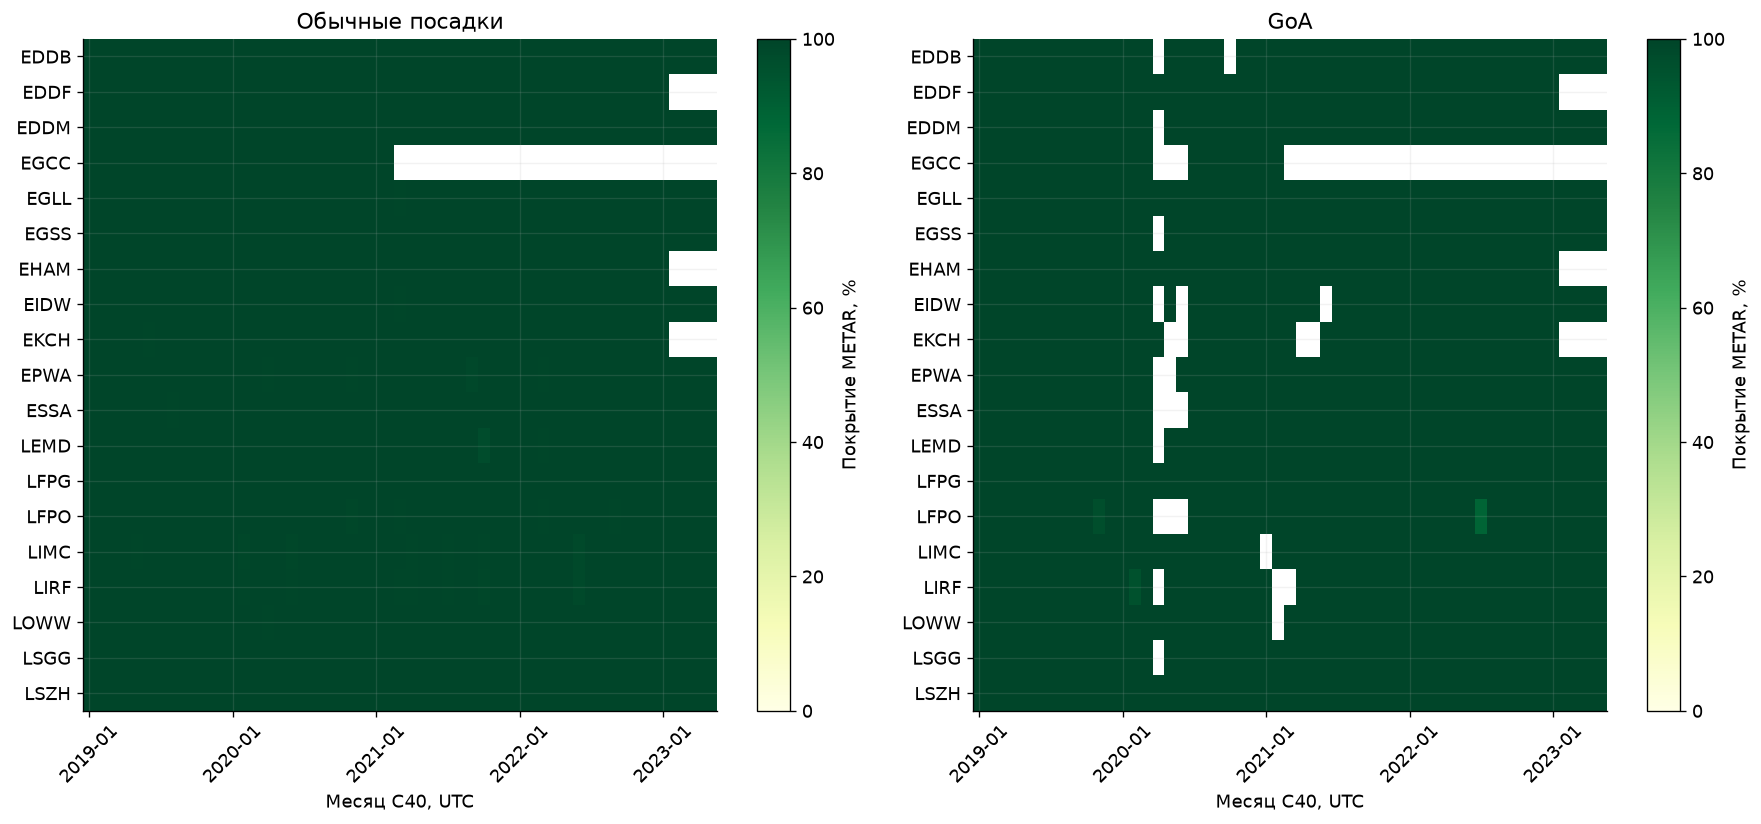

,airport,GoA,total,candidates,coverage_percent
0,EDDB,False,147909,147886,99.984450
1,EDDB,True,427,427,100.000000
2,EDDF,False,603076,603019,99.990548
3,EDDF,True,1884,1884,100.000000
4,EDDM,False,441910,441883,99.993890
...,...,...,...,...,...
33,LOWW,True,1021,1021,100.000000
34,LSGG,False,204844,204844,100.000000
35,LSGG,True,528,528,100.000000
36,LSZH,False,315829,315775,99.982902


,airport,month,GoA,total,candidates,coverage_percent
97368,LFPO,2022-07,True,26,23,88.461538
108924,LIRF,2020-02,True,23,22,95.652174
92544,LFPO,2019-11,True,26,25,96.153846
80682,LEMD,2021-10,False,9589,9302,97.006987
112290,LIRF,2022-06,False,7591,7454,98.195231
104874,LIMC,2022-06,False,5247,5158,98.303793
65670,EPWA,2021-09,False,4228,4175,98.746452
110814,LIRF,2021-10,False,4347,4301,98.941799
101346,LIMC,2020-02,False,4654,4609,99.033090
101490,LIMC,2020-06,False,1585,1570,99.053628


,total,no_previous,older_than_60,older_than_90,ambiguous
airport,,,,,
EDDB,148336,0,23,16,0
EDDF,604960,0,57,21,0
EDDM,443203,0,27,13,0
EGCC,87435,0,9,1,0
EGLL,631718,0,57,12,0
EGSS,221348,0,18,2,0
EHAM,561481,0,60,26,0
EIDW,263879,0,59,26,0
EKCH,243272,0,113,33,0


In [3]:
base=scenario.loc[scenario.latency_minutes.eq(0)&scenario.maximum_age_minutes.eq(60)&scenario.quality.eq('observation')&scenario.exclude_cor.eq(False)]
fig,axes=plt.subplots(1,2,figsize=(15,7))
for ax,label in zip(axes,[False,True]):
    part=base.loc[base.GoA.eq(label)].copy()
    part['coverage']=100*part.candidates/part.total
    table=part.pivot(index='airport',columns='month',values='coverage').sort_index()
    im=ax.imshow(np.ma.masked_invalid(table.values),vmin=0,vmax=100,cmap='YlGn',aspect='auto')
    ticks=list(range(0,len(table.columns),12))
    ax.set(yticks=range(len(table)),yticklabels=table.index,xticks=ticks,xticklabels=table.columns[ticks],title='GoA' if label else 'Обычные посадки',xlabel='Месяц C40, UTC')
    ax.tick_params(axis='x',rotation=45)
    fig.colorbar(im,ax=ax,label='Покрытие METAR, %')
save('24_full_monthly_coverage')
airport=base.groupby(['airport','GoA'])[['total','candidates']].sum().reset_index()
airport['coverage_percent']=100*airport.candidates/airport.total
display(airport)
monthly=base.assign(coverage_percent=100*base.candidates/base.total)
display(monthly.sort_values(['coverage_percent','airport','month']).head(20)[
    ['airport','month','GoA','total','candidates','coverage_percent']])
display(pd.read_csv(R/'12_full_age_and_missingness.csv').groupby('airport')[
    ['total','no_previous','older_than_60','older_than_90','ambiguous']].sum())


## 3. Чувствительность к давности и предполагаемой задержке

Повторный выбор при задержке оценивает предположение о доступности, а не
фактическое время публикации. Пропуски и COR не заменяются более старой погодой
ради улучшения качества. Основные поля и полный разбор представлены отдельно.


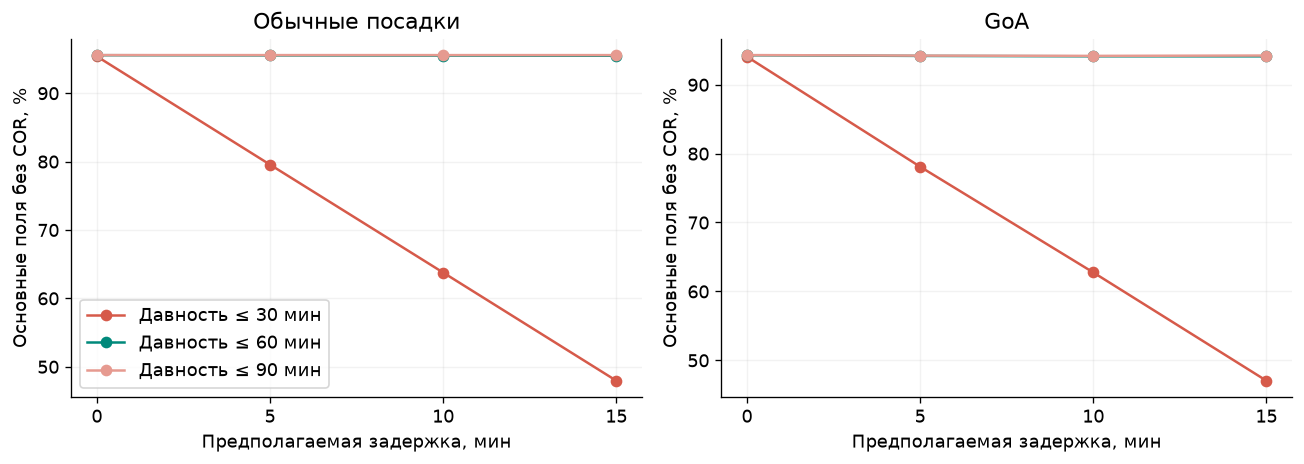

In [4]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,label in zip(axes,[False,True]):
    for age,color in [(30,CORAL),(60,GREEN),(90,LIGHT_CORAL)]:
        part=summary.loc[summary.GoA.eq(label)&summary.maximum_age_minutes.eq(age)&summary.quality.eq('core_validated')&summary.exclude_cor.eq(True)].sort_values('latency_minutes')
        ax.plot(part.latency_minutes,part.coverage_percent,marker='o',color=color,label=f'Давность ≤ {age} мин')
    ax.set(title='GoA' if label else 'Обычные посадки',xlabel='Предполагаемая задержка, мин',ylabel='Основные поля без COR, %',xticks=[0,5,10,15])
axes[0].legend(loc='lower left')
save('25_full_latency_age_sensitivity')


## 4. Замечания декодирования и исходные сообщения

Полный реестр сохранен в [CSV](../reports/12_full_residuals.csv). Здесь показаны
числа по станциям и группам замечаний, а также первые 30 сообщений по станции
и времени без отбора по исходу. Положительная проверка префикса до QNH не
исправляет исходный текст и не подтверждает валидность дополнительных групп.


,station,decode_issues,reports,matched_rows,matched_go_arounds
0,EDDB,parser_error,9,22,0
1,EDDB,parser_value_disagreement_cloud_layers,171,217,0
2,EDDF,parser_error,20,215,2
3,EDDF,parser_value_disagreement_cloud_layers,63,414,3
4,EDDF,unclassified_weather_after_qnh;parser_error,2,14,0
...,...,...,...,...,...
83,LSGG,visibility_format_outside_pilot_scope;qnh_group_missing_or_multiple,5,8,0
84,LSZH,parser_error,62,46,1
85,LSZH,parser_error;wind_group_missing_or_multiple;visibility_format_outside_pilot_scope,1,13,0
86,LSZH,parser_error;wind_group_missing_or_multiple;visibility_format_outside_pilot_scope;qnh_group_miss...,1,0,0


station,metar_utc,metar,decode_issues,core_issues,matched_rows,matched_go_arounds
EDDB,2019-01-12 10:20:00+00:00,EDDB 121020Z AUTO 27016KT //// R25R/P2000N R25L/P2000N // ///////// 06/04 Q1012 TEMPO 3000 -RADZ BKN007,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,2,0
EDDB,2019-01-17 12:20:00+00:00,EDDB 171220Z AUTO 25014KT //// R25R/P2000N R25L/P2000N // ///////// 07/01 Q0999 TEMPO 24015G25KT,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,3,0
EDDB,2019-01-25 20:50:00+00:00,EDDB 252050Z AUTO 23009KT //// R25R/P2000N R25L/P2000N // ///////// M03/M08 Q1011 NOSIG,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,3,0
EDDB,2019-02-08 10:50:00+00:00,EDDB 081050Z AUTO 22018KT //// R25R/P2000N R25L/P2000N // ///////// 07/02 Q1015 NOSIG,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,2,0
EDDB,2019-02-17 03:50:00+00:00,EDDB 170350Z AUTO 24003KT 190V250 //// R25R/P2000N R25L/P2000N // ///////// M00/M02 Q1025 NOSIG,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,0,0
EDDB,2019-02-22 16:50:00+00:00,EDDB 221650Z AUTO 10005KT //// R07L/P2000N R25L/P2000N // ///////// 01/M08 Q1042 NOSIG,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,4,0
EDDB,2019-03-04 17:50:00+00:00,EDDB 041750Z AUTO 25016KT //// R25R/P2000N R25L/P2000N // ///////// 06/04 Q0992 TEMPO 26025G35KT,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,4,0
EDDB,2019-03-09 22:20:00+00:00,EDDB 092220Z AUTO 28024G34KT //// R25R/P2000N R25L/P2000N // ///////// 05/01 Q1007 NOSIG,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,1,0
EDDB,2019-03-15 17:50:00+00:00,EDDB 151750Z AUTO 27015KT //// R25R/P2000N R25L/P2000N // ///////// 10/06 Q0994 TEMPO 22020G30KT,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,0,0
EDDB,2019-03-16 06:20:00+00:00,EDDB 160620Z AUTO 27014KT //// R25R/P2000N R25L/P2000N // ///////// 06/01 Q1005 TEMPO 28020G30KT,parser_value_disagreement_cloud_layers,parser_value_disagreement_cloud_layers,2,0


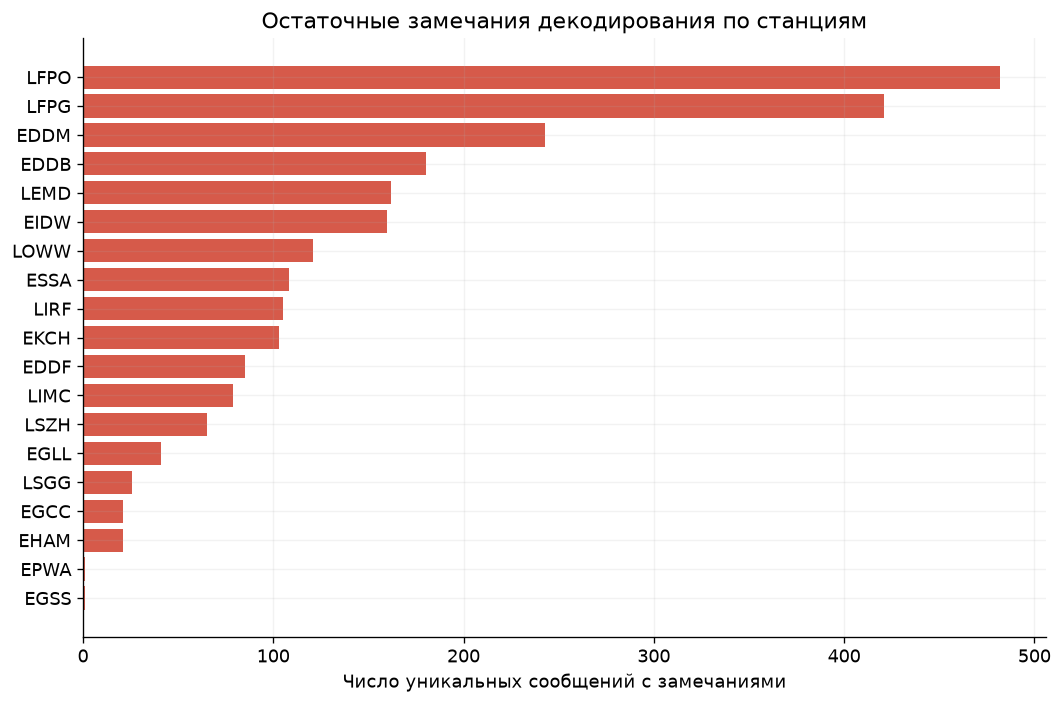

,airport,year,month,old_only,new_only
0,EDDF,2019,2019-01,0,0
1,EDDF,2019,2019-07,0,0
2,EGCC,2019,2019-01,0,0
3,EGCC,2019,2019-07,0,0
4,EGLL,2019,2019-01,0,0
5,EGLL,2019,2019-07,0,0
6,EHAM,2019,2019-01,0,0
7,EHAM,2019,2019-07,0,0
8,LEMD,2019,2019-01,0,0
9,LEMD,2019,2019-07,0,0


field,cloud_ceiling_ft,dewpoint_c,qnh_hpa,temperature_c,visibility_m,wind_gust_kt,wind_speed_kt
airport,,,,,,,
EDDB,31.10,100.00,100.00,100.00,99.86,1.59,100.00
EDDF,28.65,100.00,100.00,100.00,99.94,2.10,100.00
EDDM,25.76,100.00,100.00,100.00,99.76,1.72,100.00
EGCC,39.08,100.00,99.99,100.00,100.00,3.01,100.00
EGLL,37.42,100.00,100.00,100.00,99.99,2.92,99.99
EGSS,38.04,100.00,99.99,100.00,100.00,2.53,100.00
EHAM,28.62,100.00,100.00,100.00,100.00,2.91,100.00
EIDW,68.72,99.99,100.00,99.99,99.91,10.06,99.99
EKCH,56.61,100.00,100.00,100.00,100.00,2.94,100.00


,minimum,maximum
field,,
cloud_ceiling_ft,100.0,90000.0
dewpoint_c,-80.0,27.0
qnh_hpa,122.0,1202.0
temperature_c,-22.0,43.0
visibility_m,50.0,10000.0
wind_gust_kt,11.0,75.0
wind_speed_kt,0.0,50.0


metar_id,station,metar_utc,metar,qnh_hpa,dewpoint_c,cloud_ceiling_ft,decoded_candidate,core_validated,review_reason,extreme_value,linked_rows,linked_go_arounds,linked_rows_within_60min
c26eff211c7d01b9563f39a342996cc4fc751b08d0162ad35a66bc39ea7327c0,EHAM,2021-01-19 11:55:00+00:00,EHAM 191155Z 25018G30KT 210V280 7000 -DZRA FEW006 BKN008 10/M80 Q1002 BECMG 9999 NSW BKN014,1002.0,-80.0,800.0,True,True,dewpoint_c_minimum,-80.0,2,0,2
5e7f4b1536d4b5716a326f9e74af7805bdf2af24f258cae46db4b1fa82cbc729,ESSA,2021-04-08 13:50:00+00:00,ESSA 081350Z 32005KT 9999 FEW012 BKN900 06/M07 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,-7.0,90000.0,True,True,cloud_ceiling_ft_maximum,90000.0,3,0,3
fd337c55fdbd3a9b8a4b6fcf671dc2da6039f6564feb52a8187854f6bd4b1692,LIMC,2020-11-01 18:20:00+00:00,LIMC 011820Z VRB01KT 0100 R35R/0400D R17L/0400D R35L/0500N FG VV001 11/11 Q0122 NOSIG,122.0,11.0,NaN,True,True,qnh_hpa_minimum,122.0,1,0,1
05e9ce88b3ad238073239e9f554be019f01f07570da856de79af1853a3539fef,LIMC,2020-10-30 12:20:00+00:00,LIMC 301220Z 24003KT CAVOK 17/11 Q1202 NOSIG,1202.0,11.0,NaN,True,True,qnh_hpa_maximum,1202.0,1,0,1


,wind_unit,qnh_unit,visibility_unit,reports,auto_reports,cor_reports
0,,,,3,0,0
1,,hPa,,26,5,7
2,KMH,hPa,M,1,0,0
3,KT,,,8,5,0
4,KT,,M,15,3,2
5,KT,hPa,,109,4,12
6,KT,hPa,M,1414866,320149,41887
7,KT,inHg,M,1,0,0


In [5]:
display(residual.groupby(['station','decode_issues']).agg(reports=('metar_id','size'),
    matched_rows=('matched_rows','sum'),matched_go_arounds=('matched_go_arounds','sum')).reset_index())
readable_table(residual.sort_values(['station','metar_utc']).head(30)[['station','metar_utc','metar','decode_issues','core_issues','matched_rows','matched_go_arounds']])
groups=residual.groupby('station').size().sort_values()
fig,ax=plt.subplots(figsize=(9,6))
ax.barh(groups.index,groups.values,color=CORAL)
ax.set(xlabel='Число уникальных сообщений с замечаниями',title='Остаточные замечания декодирования по станциям')
save('26_full_decode_residuals')
comparisons=[dict(airport=j['airport'],year=j['year'],**c) for j in progress['jobs'] for c in j['pilot_snapshot_comparison']]
display(pd.DataFrame(comparisons))
completeness=pd.read_csv(R/'12_full_field_completeness.csv')
filled=completeness.groupby(['airport','field'])[['total','present']].sum().reset_index()
filled['present_percent']=100*filled.present/filled.total
display(filled.pivot(index='airport',columns='field',values='present_percent').round(2))
display(completeness.groupby('field').agg(minimum=('minimum','min'),maximum=('maximum','max')))
readable_table(pd.read_csv(R/'12_full_extreme_value_examples.csv'))
formats=pd.read_csv(R/'12_full_formats.csv',keep_default_na=False)
display(formats.groupby(['wind_unit','qnh_unit','visibility_unit'])[['reports','auto_reports','cor_reports']].sum().reset_index())


## 5. Итоговые границы применимости

Завершение загрузки не означает готовность модели к обучению. Историческая
доступность METAR и целевого аэропорта к C40 не подтверждена. Пропуски,
замечания качества и изменение состава движения требуют отдельных решений.
Новые исключения и автоматическое исправление источника не применялись.
Числовая достоверность не подтверждается синтаксической проверкой: QNH 122 и
1202 гПа, точка росы −80 °C и BKN900 рассмотрены отдельно в
[ноутбуке 09](09_numeric_anomaly_audit.ipynb). Значения сохранены без исправления.
Остаточные форматы и правило использования погодных признаков требуют отдельного решения.

Аэропорт назначения принят заранее известным к C40 как исследовательское
допущение; фактический внешний канал должен быть подтвержден для применения.
[Допущения доступности](../reports/13_feature_availability_assumptions.md).


In [6]:
import unittest,test_decode_metar,test_full_weather_pipeline
outcome=unittest.TextTestRunner(stream=sys.stdout,verbosity=1).run(unittest.TestSuite([
    unittest.defaultTestLoader.loadTestsFromModule(m) for m in [test_decode_metar,test_full_weather_pipeline]]))
assert outcome.wasSuccessful()
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==protocol['input_sha256']


.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 20 tests in 0.011s

OK
